In [53]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [135]:
df=pd.read_csv("shop_smart_ecommerce.csv")

In [70]:
df.sample(5)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
2336,7,145.000000,0,0.0,7,96.000000,0.000000,0.013333,0.000000,0.0,May,2,2,1,4,New_Visitor,False,False
11240,0,0.000000,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,Nov,3,2,3,13,Returning_Visitor,False,False
2537,6,140.000000,1,12.0,52,723.315873,0.001212,0.006277,4.504382,0.0,May,3,2,4,11,Returning_Visitor,False,False
5149,6,169.566667,0,0.0,21,1853.535714,0.000000,0.021727,0.000000,0.0,May,3,2,4,4,Returning_Visitor,True,False
5865,0,0.000000,0,0.0,16,196.333333,0.012500,0.023958,0.000000,0.0,Oct,1,1,3,2,Returning_Visitor,True,False


Text(0.5, 1.0, 'Is Revenue grnerated or Not ?')

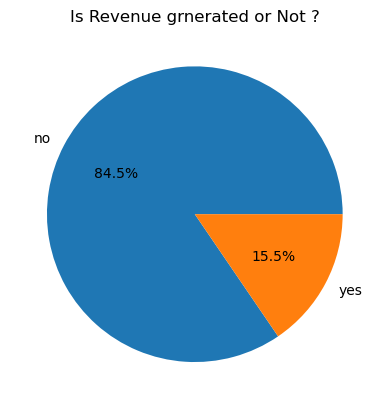

In [13]:
classes_count=df["Revenue"].value_counts()
plt.pie(classes_count,labels=["no","yes"],autopct="%1.1f%%")
plt.title("Is Revenue grnerated or Not ?")

<Axes: xlabel='ProductRelated_Duration', ylabel='Count'>

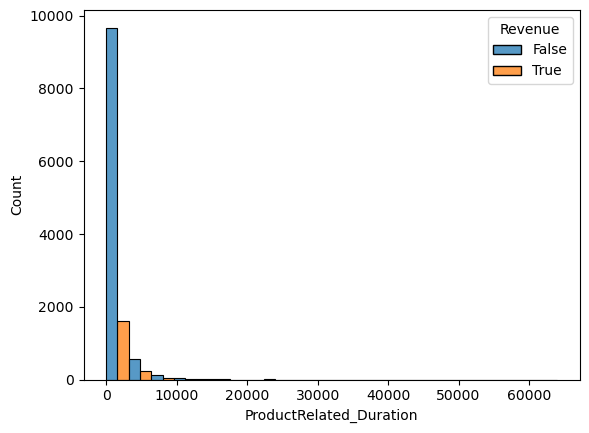

In [15]:
sns.histplot(
    data=df,
    x="ProductRelated_Duration",
    hue="Revenue",
    bins=20,
    multiple="dodge"
)

[Text(0, 0, '10551'), Text(0, 0, '1694'), Text(0, 0, '85')]

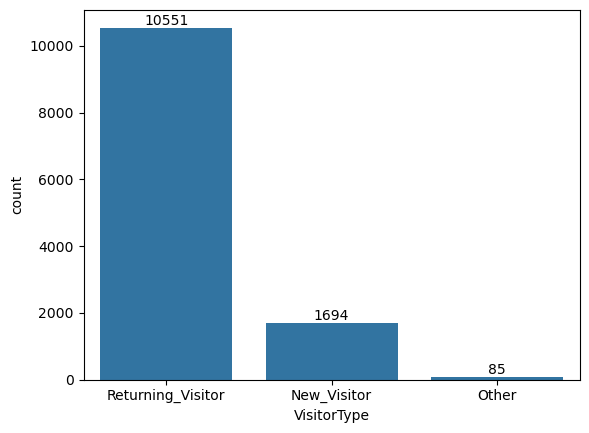

In [16]:
edu_cnt = df["VisitorType"].value_counts()
ax = sns.barplot(edu_cnt)
ax.bar_label(ax.containers[0])

<Axes: xlabel='VisitorType', ylabel='Count'>

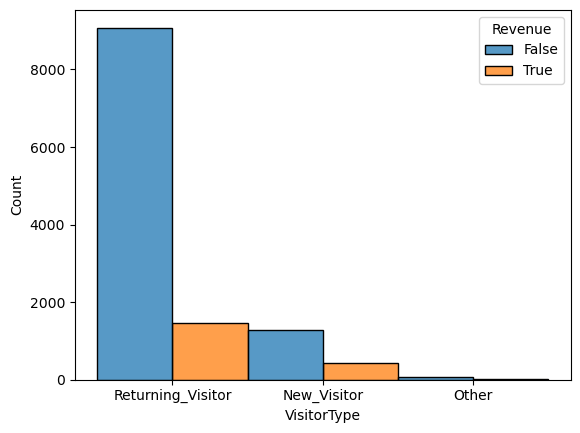

In [19]:
sns.histplot(
    data=df,
    x="VisitorType",
    hue="Revenue",
    
    multiple="dodge"
)

In [136]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
le=LabelEncoder()
df["Revenue"]=le.fit_transform(df["Revenue"])
df["Weekend"]=le.fit_transform(df["Weekend"])
df["VisitorType"]=le.fit_transform(df["VisitorType"])
df["Month"]=le.fit_transform(df["Month"])

<Axes: >

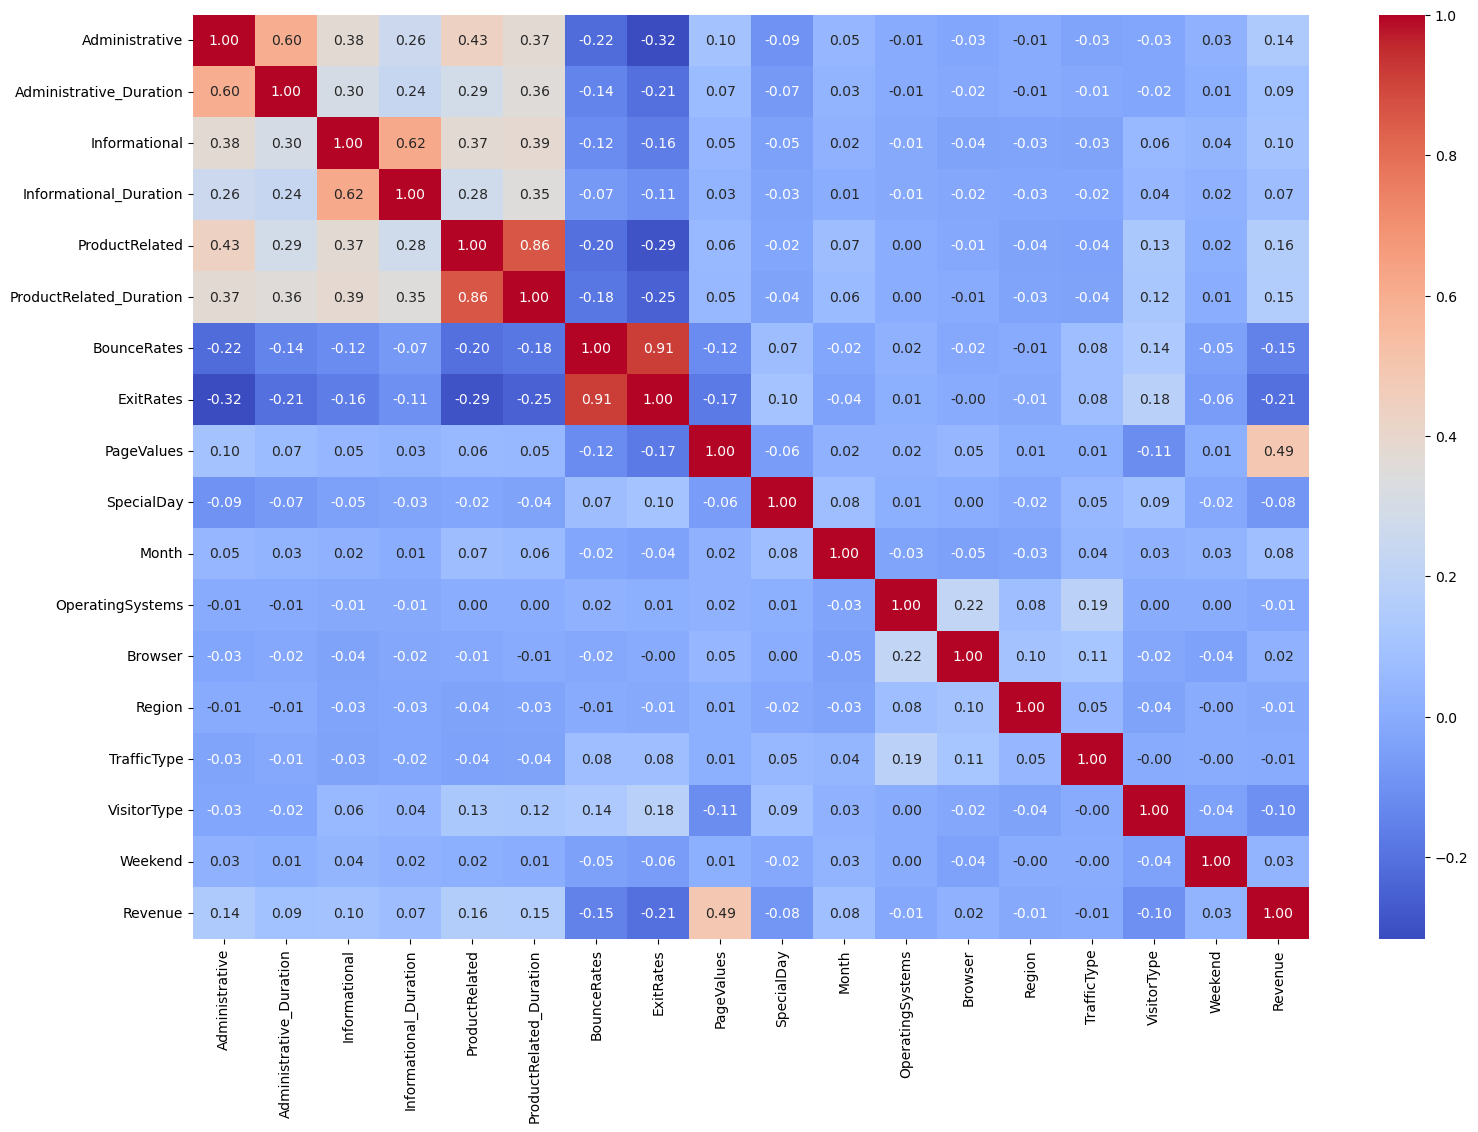

In [49]:
num_cols=df.select_dtypes(include="number")
coor_matrix=num_cols.corr()
plt.figure(figsize=(18,12))
sns.heatmap(
    coor_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
    
)

In [72]:
num_cols.corr()["Revenue"].sort_values(ascending=False)

Revenue                    1.000000
PageValues                 0.492569
ProductRelated             0.158538
ProductRelated_Duration    0.152373
Administrative             0.138917
Informational              0.095200
Administrative_Duration    0.093587
Month                      0.080150
Informational_Duration     0.070345
Weekend                    0.029295
Browser                    0.023984
TrafficType               -0.005113
Region                    -0.011595
OperatingSystems          -0.014668
SpecialDay                -0.082305
VisitorType               -0.104726
BounceRates               -0.150673
ExitRates                 -0.207071
Name: Revenue, dtype: float64

In [137]:
X=df.drop("Revenue",axis=1)
y=df["Revenue"]

In [138]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [139]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [140]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(max_depth=8)
model.fit(X_train_scaled, y_train)
y_pred=model.predict(X_test_scaled)

In [141]:
from sklearn.metrics import confusion_matrix,precision_score,accuracy_score,recall_score,f1_score
print("confusion_matrix:",confusion_matrix(y_test,y_pred))
print("precision_score:",precision_score(y_test,y_pred))
print("accuracy_score:",accuracy_score(y_test,y_pred))
print("recall_score:",recall_score(y_test,y_pred))
print("f1_score:",f1_score(y_test,y_pred))

confusion_matrix: [[1974   81]
 [ 184  227]]
precision_score: 0.737012987012987
accuracy_score: 0.8925385239253852
recall_score: 0.5523114355231143
f1_score: 0.631432545201669
